<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Mini Project4 - Clustering</h3>
</div>

## Importing the libraries

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
import warnings
warnings.filterwarnings('ignore')

## Load and Prepare Data

In [3]:
# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

In [4]:
# Display first 5 rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
# Check dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [6]:
# Rename columns for better readability
df.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']
df.head(3)

,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6


## EDA

In [7]:
# Summary statistics
df.describe()

,CustomerID,Age,Annual_Income,Spending_Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
# Count unique values
df.nunique()

CustomerID        200
Gender              2
Age                51
Annual_Income      64
Spending_Score     84
dtype: int64

In [9]:
# Check for null values
df.isnull().sum()

CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

In [10]:
# Check for missing values using isna
df.isna().sum()

CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

In [11]:
# Impute missing values with median/mode to ensure data integrity
df['Annual_Income'] = df['Annual_Income'].fillna(df['Annual_Income'].median())
df['Spending_Score'] = df['Spending_Score'].fillna(df['Spending_Score'].median())
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

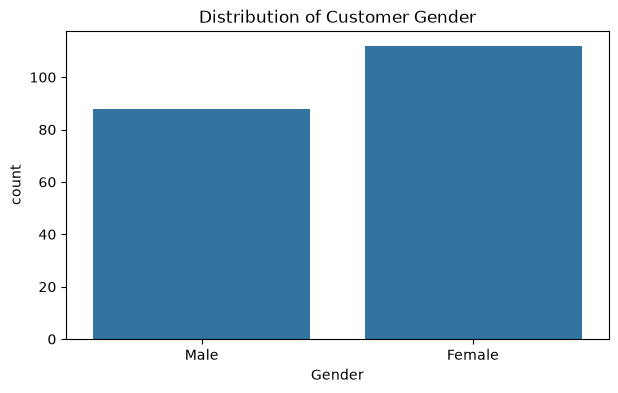

In [12]:
# Visualize gender distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Gender')
plt.title('Distribution of Customer Gender')
plt.show()

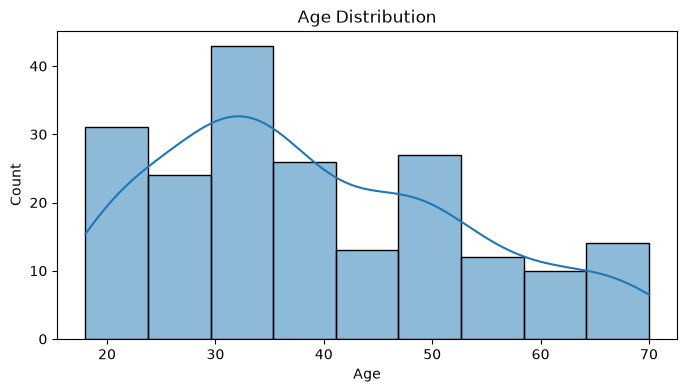

In [13]:
# Visualize age distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

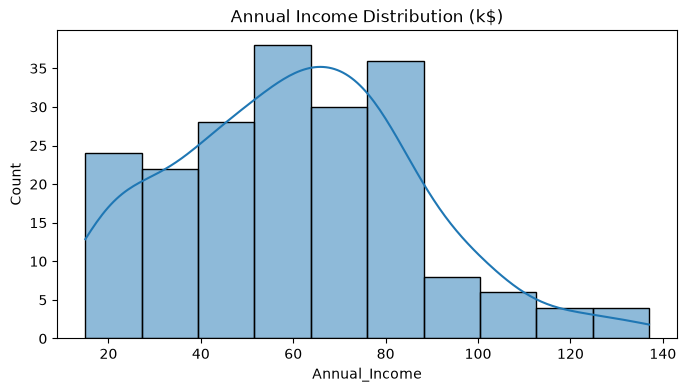

In [14]:
# Visualize Annual Income distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Annual_Income'], kde=True)
plt.title('Annual Income Distribution (k$)')
plt.show()

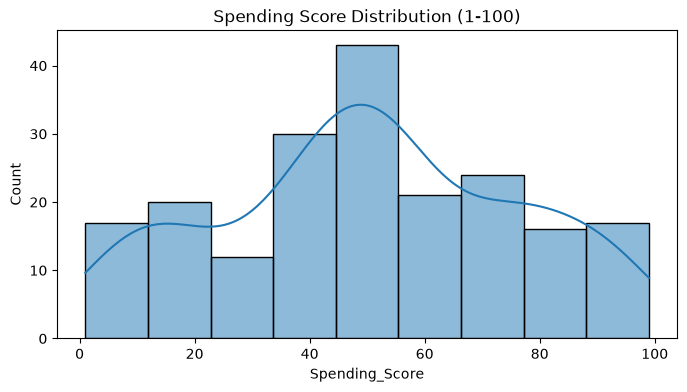

In [15]:
# Visualize Spending Score distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Spending_Score'], kde=True)
plt.title('Spending Score Distribution (1-100)')
plt.show()

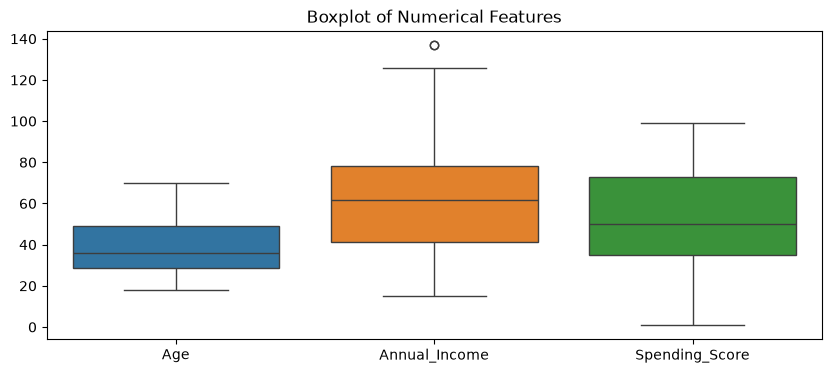

In [16]:
# Check for outliers using boxplots
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['Age', 'Annual_Income', 'Spending_Score']])
plt.title('Boxplot of Numerical Features')
plt.show()

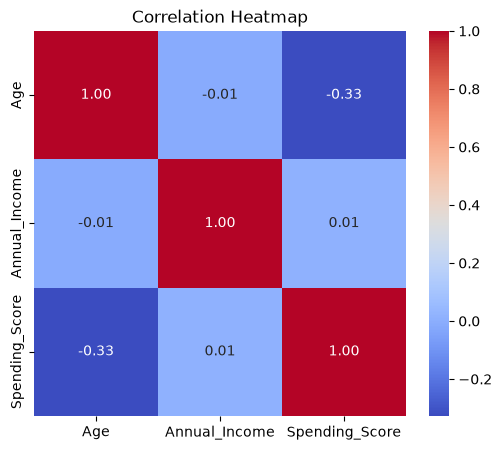

In [17]:
# Correlation heatmap
plt.figure(figsize=(6, 5))
numeric_cols = ['Age', 'Annual_Income', 'Spending_Score']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

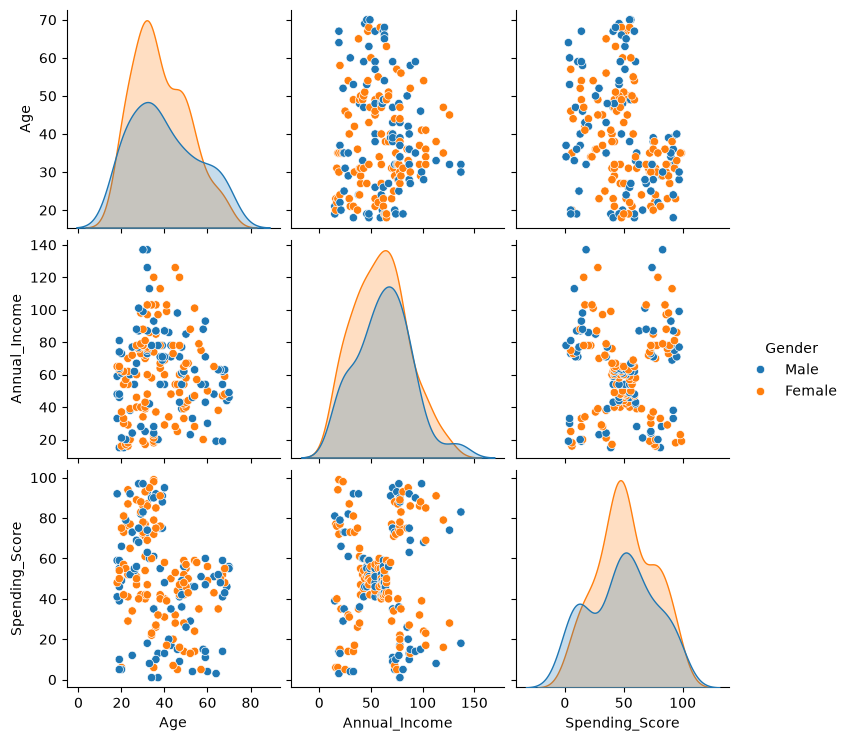

In [18]:
# Pairplot to see relationships between features
sns.pairplot(df, vars=['Age', 'Annual_Income', 'Spending_Score'], hue='Gender')
plt.show()

## Data Preprocessing

In [19]:
# Encode categorical gender variable
gender_dummies = pd.get_dummies(df['Gender'], prefix='Gender', drop_first=True)
df_encoded = pd.concat([df, gender_dummies], axis=1)
df_encoded.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Gender_Male
0,1,Male,19,15,39,True
1,2,Male,21,15,81,True
2,3,Female,20,16,6,False
3,4,Female,23,16,77,False
4,5,Female,31,17,40,False


In [20]:
# Select features for clustering (excluding CustomerID)
features = ['Annual_Income', 'Spending_Score']
X = df_encoded[features].values

In [21]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Strorytelling - Visualization

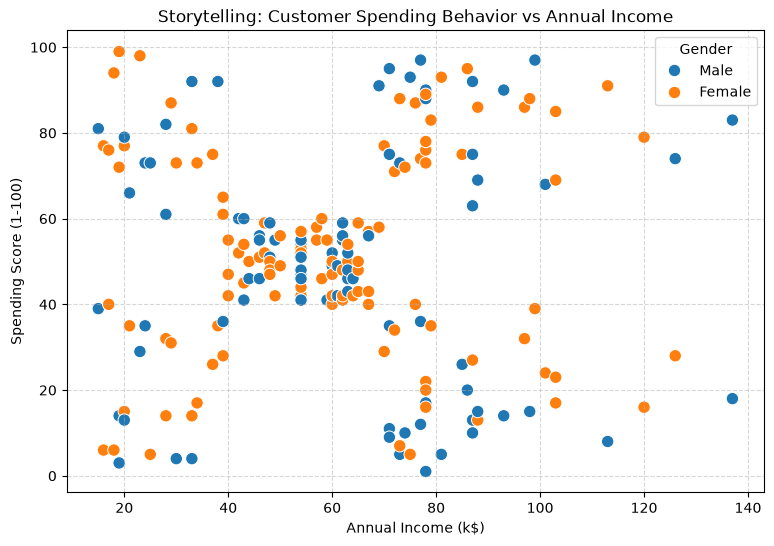

In [22]:
# Visualize Spending Score vs Annual Income
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Annual_Income', y='Spending_Score', hue='Gender', s=80)
plt.title('Storytelling: Customer Spending Behavior vs Annual Income')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

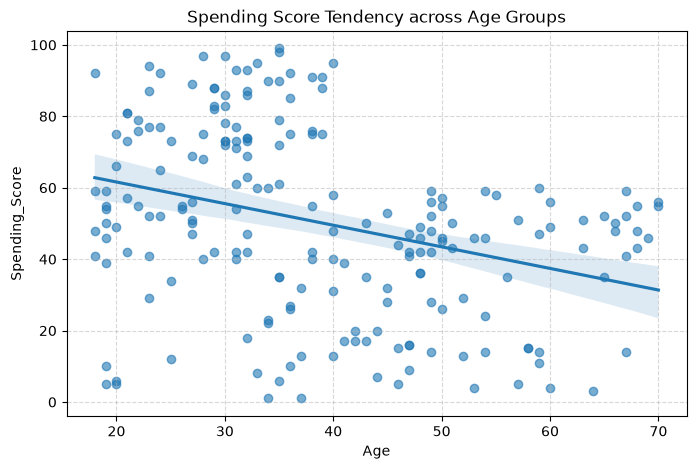

In [23]:
# Trend of spending score across age
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Age', y='Spending_Score', scatter_kws={'alpha': 0.6})
plt.title('Spending Score Tendency across Age Groups')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [24]:
# Compare means by gender
summary_by_gender = df.groupby('Gender')[['Age', 'Annual_Income', 'Spending_Score']].mean()
summary_by_gender

,Age,Annual_Income,Spending_Score
Gender,,,
Female,38.098214,59.250000,51.526786
Male,39.806818,62.227273,48.511364


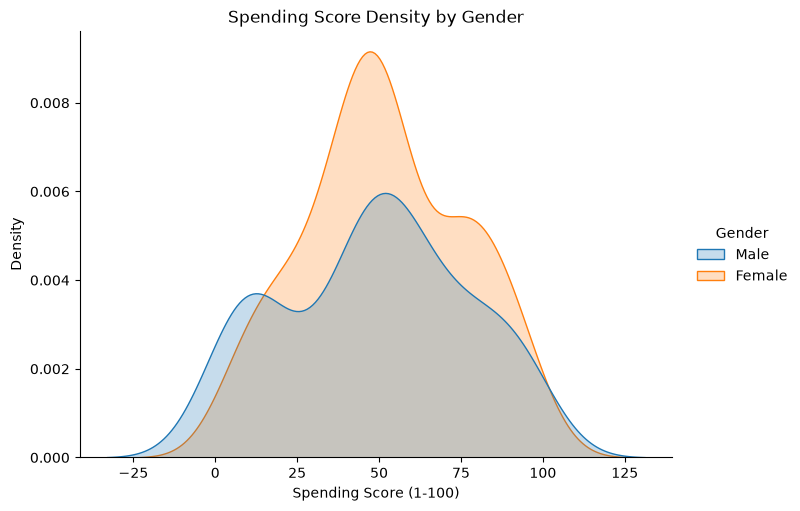

In [25]:
# Storytelling: Distribution of Spending Score across Genders using displot with fill=True
sns.displot(data=df, x='Spending_Score', hue='Gender', kind='kde', fill=True, height=5, aspect=1.4)
plt.title('Spending Score Density by Gender')
plt.xlabel('Spending Score (1-100)')
plt.show()

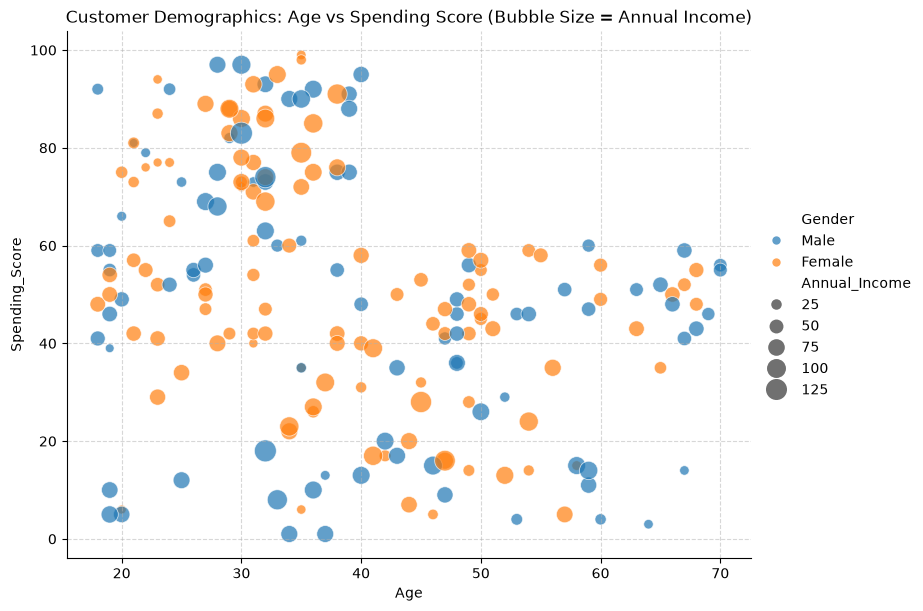

In [26]:
# Storytelling: Multi-variable relationship using relplot (Age vs Spending Score scaled by Income)
sns.relplot(
    data=df, 
    x='Age', 
    y='Spending_Score', 
    hue='Gender', 
    size='Annual_Income', 
    sizes=(40, 250), 
    alpha=0.7, 
    height=6, 
    aspect=1.3
)
plt.title('Customer Demographics: Age vs Spending Score (Bubble Size = Annual Income)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

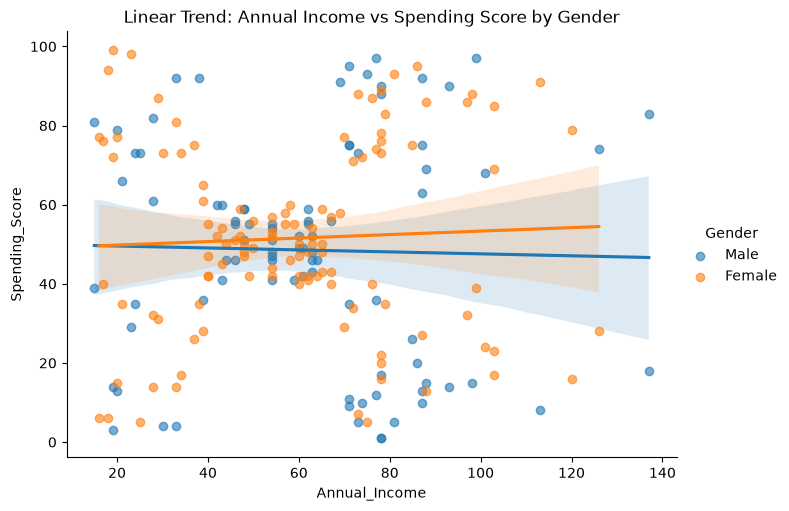

In [27]:
# Storytelling: Linear relationship analysis separated by Gender using lmplot
sns.lmplot(
    data=df, 
    x='Annual_Income', 
    y='Spending_Score', 
    hue='Gender', 
    aspect=1.4, 
    height=5, 
    scatter_kws={'alpha': 0.6}
)
plt.title('Linear Trend: Annual Income vs Spending Score by Gender')
plt.show()

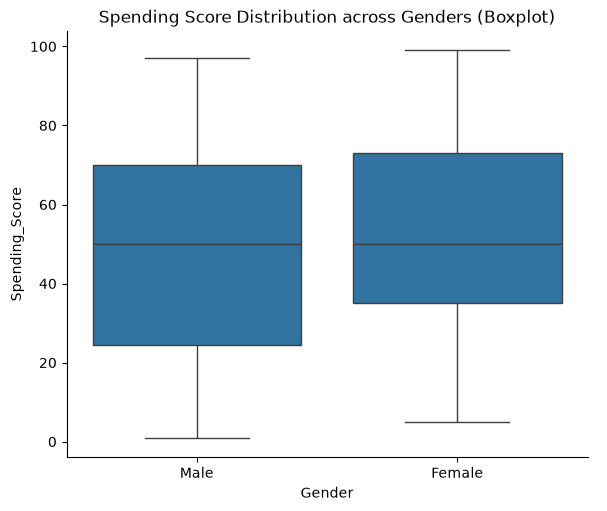

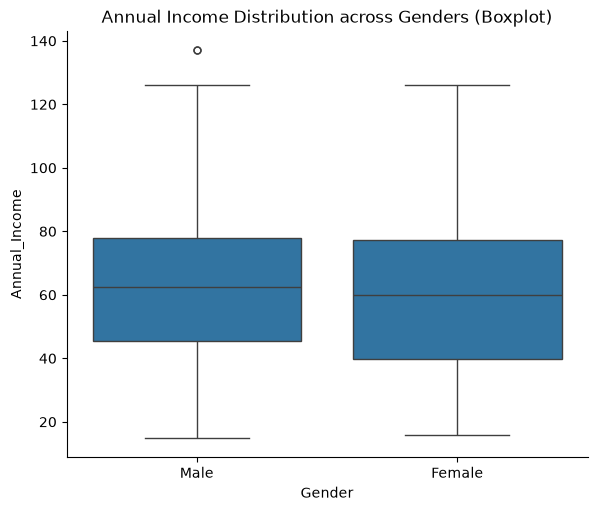

In [28]:
# Storytelling: Comparing distributions across Genders with catplot (box & strip view)
sns.catplot(data=df, x='Gender', y='Spending_Score', kind='box', height=5, aspect=1.2)
plt.title('Spending Score Distribution across Genders (Boxplot)')
plt.show()

sns.catplot(data=df, x='Gender', y='Annual_Income', kind='box', height=5, aspect=1.2)
plt.title('Annual Income Distribution across Genders (Boxplot)')
plt.show()

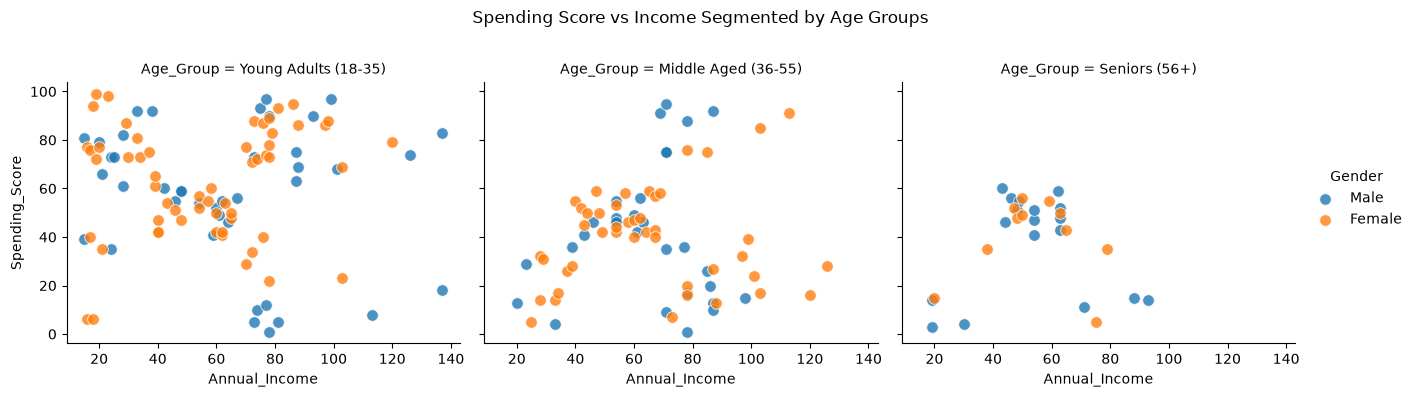

In [29]:
# Storytelling: Faceted analysis across Age Categories using FacetGrid
# Segmenting customers into three primary age generations
df['Age_Group'] = pd.cut(df['Age'], bins=[17, 35, 55, 100], labels=['Young Adults (18-35)', 'Middle Aged (36-55)', 'Seniors (56+)'])

g = sns.FacetGrid(df, col='Age_Group', hue='Gender', height=4, aspect=1.1)
g.map(sns.scatterplot, 'Annual_Income', 'Spending_Score', alpha=0.8, s=70)
g.add_legend()
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle('Spending Score vs Income Segmented by Age Groups')
plt.show()

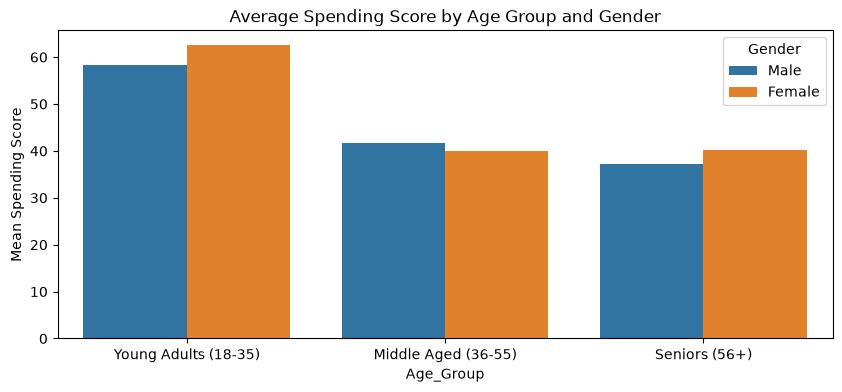

In [30]:
# Storytelling: Spending and Income comparison across defined Age Groups
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x='Age_Group', y='Spending_Score', hue='Gender', ci=None)
plt.title('Average Spending Score by Age Group and Gender')
plt.ylabel('Mean Spending Score')
plt.show()

## Train the Model (Clustering)

In [31]:
# Determine optimal K using Elbow method
inertia_list = []
k_range = range(1, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia_list.append(kmeans_temp.inertia_)

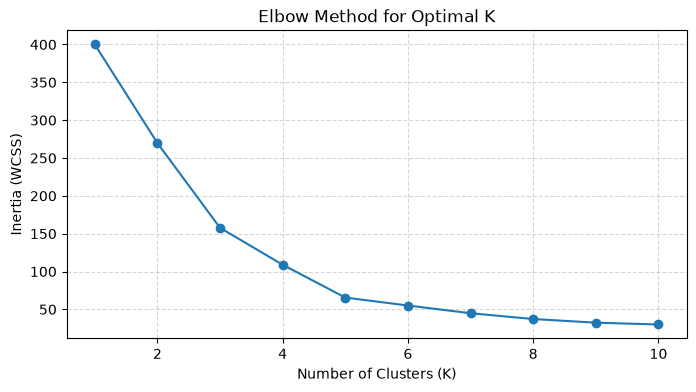

In [32]:
# Plot Elbow curve
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia_list, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [33]:
# Verify optimal K with Silhouette scores
for k in range(2, 8):
    temp_km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = temp_km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f'K = {k} -> Silhouette Score = {score:.4f}')

K = 2 -> Silhouette Score = 0.3213
K = 3 -> Silhouette Score = 0.4666
K = 4 -> Silhouette Score = 0.4939
K = 5 -> Silhouette Score = 0.5547
K = 6 -> Silhouette Score = 0.5399
K = 7 -> Silhouette Score = 0.5281


In [34]:
# Train final K-Means model with optimal K=5
k_optimal = 5
kmeans_model = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_scaled)

In [35]:
# Assign cluster labels to original dataframe
df['Cluster'] = cluster_labels
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,Age_Group,Cluster
0,1,Male,19,15,39,Young Adults (18-35),4
1,2,Male,21,15,81,Young Adults (18-35),2
2,3,Female,20,16,6,Young Adults (18-35),4
3,4,Female,23,16,77,Young Adults (18-35),2
4,5,Female,31,17,40,Young Adults (18-35),4


In [36]:
# Inverse transform cluster centers to original scale
cluster_centers_original = scaler.inverse_transform(kmeans_model.cluster_centers_)
cluster_centers_df = pd.DataFrame(cluster_centers_original, columns=['Annual_Income', 'Spending_Score'])
cluster_centers_df.index.name = 'Cluster'
cluster_centers_df

,Annual_Income,Spending_Score
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


In [37]:
# Profile the clusters
cluster_profile = df.groupby('Cluster')[['Age', 'Annual_Income', 'Spending_Score']].mean()
cluster_profile['Customer_Count'] = df['Cluster'].value_counts()
cluster_profile

,Age,Annual_Income,Spending_Score,Customer_Count
Cluster,,,,
0,42.716049,55.296296,49.518519,81
1,32.692308,86.538462,82.128205,39
2,25.272727,25.727273,79.363636,22
3,41.114286,88.200000,17.114286,35
4,45.217391,26.304348,20.913043,23


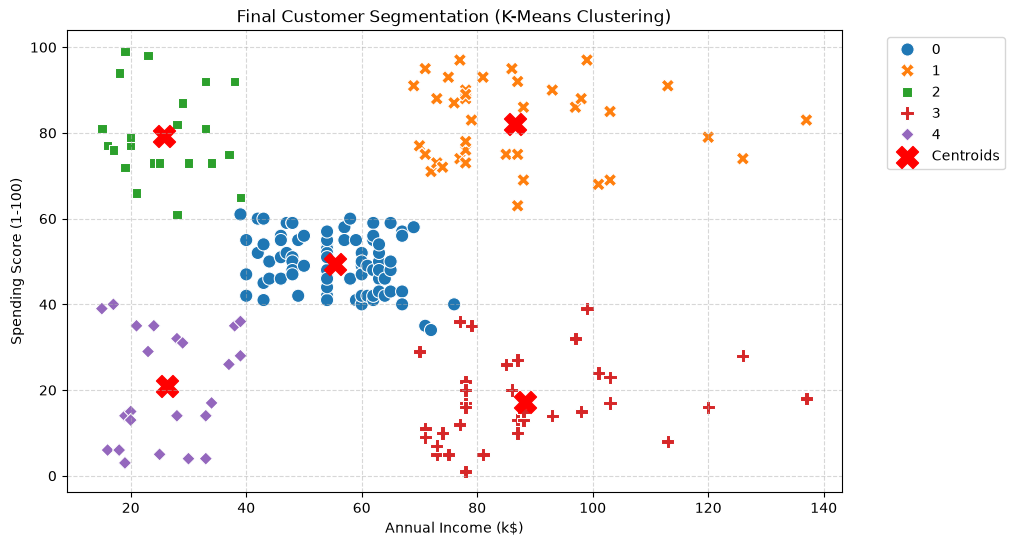

In [38]:
# Visualize final segments
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Annual_Income', 
    y='Spending_Score', 
    hue='Cluster', 
    palette='tab10', 
    s=90, 
    style='Cluster'
)

# Plot centroids
plt.scatter(
    cluster_centers_original[:, 0], 
    cluster_centers_original[:, 1], 
    s=250, 
    c='red', 
    marker='X', 
    label='Centroids'
)

plt.title('Final Customer Segmentation (K-Means Clustering)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()